In [14]:
import yfinance as yf
import numpy as np
import pandas as pd
import talib

In [ ]:
# TODO: selekcja cech + strojenie parametrów

In [15]:
data = yf.download(
  "SPY",
  period="max",
  interval="1d",
  auto_adjust=True,
  multi_level_index=False,
  progress=False,
).reset_index().rename(columns={"index": "Date"})

In [16]:
data

,Date,Close,High,Low,Open,Volume
0,1993-01-29,24.053534,24.070641,23.950887,24.070641,1003200
1,1993-02-01,24.224600,24.224600,24.070630,24.070630,480500
2,1993-02-02,24.275940,24.293048,24.156185,24.207509,201300
3,1993-02-03,24.532545,24.549653,24.293036,24.310144,529400
4,1993-02-04,24.635187,24.686510,24.344355,24.618079,531500
...,...,...,...,...,...,...
8486,2026-10-16,763.250000,773.250000,760.640015,773.239990,64384600
8487,2026-10-19,766.479980,770.460022,765.820007,767.229980,38680100
8488,2026-10-20,769.049988,772.289978,764.250000,765.859985,35048400
8489,2026-10-21,773.090027,774.440002,768.400024,771.169983,31943800


In [17]:
def rolling_percentile(series, window):
  # Percentile rank of the last value within the rolling window (0-1)
  return series.rolling(window).apply(lambda x: (x <= x[-1]).mean(), raw=True)


close = data["Close"]
high = data["High"]
low = data["Low"]

# ATR (14), used by several features
atr = talib.ATR(high, low, close, timeperiod=14)



# =========================
# DIRECTION OF THE DAY
# =========================

# Direction of day t (1.0 = green candle, -1.0 = red candle); doji (Close == Open) -> NaN
dir_day = np.sign(close - data["Open"]).replace(0, np.nan)
data["Dir"] = dir_day.astype("float32")

# Streak of consecutive days in the same direction
streak_group = (dir_day != dir_day.shift(1)).cumsum()
data["Streak"] = (dir_day.groupby(streak_group).cumcount() + 1).where(dir_day.notna()).astype("float32")

# Where the close is within the day's range, oriented in the direction of the move
# (1.0 = closed at the extreme of the move, 0.0 = closed at the opposite end)
range_size = (high - low).replace(0, np.nan)
close_pos = (close - low) / range_size
data["Close_pos_dir"] = 0.5 + (close_pos - 0.5) * dir_day



# =========================
# MOMENTUM FEATURES (IN DIRECTION OF THE DAY)
# =========================

# Returns
data["Ret_1d_dir"] = close.pct_change(1) * dir_day
data["Ret_5d_dir"] = close.pct_change(5) * dir_day
data["Ret_20d_dir"] = close.pct_change(20) * dir_day

# RSI (14), centered at 50
rsi = talib.RSI(close, timeperiod=14)

data["RSI_dir"] = (rsi - 50) * dir_day
data["RSI_chg_5d_dir"] = rsi.diff(5) * dir_day



# =========================
# TREND FEATURES (IN DIRECTION OF THE DAY)
# =========================

# Distance from moving average and slope sign
sma_50 = talib.SMA(close, timeperiod=50)
sma_200 = talib.SMA(close, timeperiod=200)

data["Dist_SMA50_dir"] = (close - sma_50) / sma_50 * dir_day
data["Dist_SMA200_dir"] = (close - sma_200) / sma_200 * dir_day

data["Slope_SMA50_dir"] = np.sign(sma_50.diff(5)) * dir_day
data["Slope_SMA200_dir"] = np.sign(sma_200.diff(5)) * dir_day

# MACD (12, 26, 9), histogram normalized by ATR
_, _, macd_hist = talib.MACD(close, fastperiod=12, slowperiod=26, signalperiod=9)
data["MACD_hist_ATR_dir"] = macd_hist / atr * dir_day

# ADX (14)
data["ADX"] = talib.ADX(high, low, close, timeperiod=14)
data["Is_trending"] = (data["ADX"] > 25).astype("float32")



# =========================
# SUPPORT / RESISTANCE FEATURES (IN DIRECTION OF THE DAY)
# =========================
for window in (20, 252):
  rolling_high = high.rolling(window).max()
  rolling_low = low.rolling(window).min()

  # Distance (in ATR) to the extreme the move is heading towards
  # green day -> distance to the N-day high, red day -> distance to the N-day low
  dist_to_extreme = np.where(dir_day > 0, rolling_high - close, close - rolling_low)
  data[f"Dist_extreme_{window}d_ATR"] = dist_to_extreme / atr

  # Did the day set a new N-day extreme in the direction of the move
  new_extreme = np.where(dir_day > 0, high >= rolling_high, low <= rolling_low)
  data[f"New_extreme_{window}d"] = pd.Series(new_extreme, index=data.index).where(dir_day.notna()).astype("float32")



# =========================
# VOLATILITY FEATURES
# =========================

# ATR relative to price
data["ATR_pct"] = atr / close

# Bollinger band width (20, 2) and its 252-day percentile
bb_upper, bb_middle, bb_lower = talib.BBANDS(close, timeperiod=20, nbdevup=2, nbdevdn=2, matype=0)
bb_width = (bb_upper - bb_lower) / bb_middle

data["BB_width"] = bb_width
data["BB_width_pctl"] = rolling_percentile(bb_width, 252)



# =========================
# TARGET
# =========================

# Does day t+1 continue the direction of day t (1.0) or not (0.0)
next_dir = dir_day.shift(-1)

data["Target"] = (next_dir == dir_day).astype("float32")
data.loc[next_dir.isna() | dir_day.isna(), "Target"] = np.nan



# =========================
# FEATURE SELECTION
# =========================
feature_cols = [
  "Dir",
  "Streak",
  "Close_pos_dir",

  "Ret_1d_dir",
  "Ret_5d_dir",
  "Ret_20d_dir",

  "RSI_dir",
  "RSI_chg_5d_dir",

  "Dist_SMA50_dir",
  "Dist_SMA200_dir",
  "Slope_SMA50_dir",
  "Slope_SMA200_dir",

  "MACD_hist_ATR_dir",
  "ADX",
  "Is_trending",

  "Dist_extreme_20d_ATR",
  "Dist_extreme_252d_ATR",
  "New_extreme_20d",
  "New_extreme_252d",

  "ATR_pct",
  "BB_width",
  "BB_width_pctl",
]

data[feature_cols] = data[feature_cols].astype("float32")

# Training set: complete features and known target
train_data = data.dropna(subset=feature_cols + ["Target"]).reset_index(drop=True)

# Live prediction row: complete features, target not known yet
live_row = data.dropna(subset=feature_cols).tail(1)

In [18]:
train_data

,Date,Close,High,Low,Open,Volume,Dir,Streak,Close_pos_dir,Ret_1d_dir,...,ADX,Is_trending,Dist_extreme_20d_ATR,New_extreme_20d,Dist_extreme_252d_ATR,New_extreme_252d,ATR_pct,BB_width,BB_width_pctl,Target
0,1994-02-23,26.499134,26.621896,26.411447,26.604359,391700,-1.0,1.0,0.583333,0.002640,...,20.749071,0.0,1.241284,0.0,12.706882,0.0,0.007998,0.034729,0.750000,1.0
1,1994-02-24,26.148396,26.411458,26.130858,26.411458,770800,-1.0,2.0,0.937500,0.013236,...,21.593866,0.0,0.078609,1.0,10.498679,0.0,0.008532,0.038158,0.797619,0.0
2,1994-02-25,26.271151,26.271151,26.130851,26.183463,531300,1.0,1.0,1.000000,0.004695,...,22.378344,0.0,3.876031,0.0,3.876031,0.0,0.008267,0.039195,0.813492,0.0
3,1994-02-28,26.271151,26.411450,26.271151,26.341301,333000,-1.0,1.0,1.000000,-0.000000,...,22.202093,0.0,0.662756,0.0,11.644217,0.0,0.008058,0.039269,0.817460,1.0
4,1994-03-01,26.165924,26.323761,26.025624,26.271149,423600,-1.0,2.0,0.529412,0.004005,...,22.911272,0.0,0.643973,1.0,10.831213,0.0,0.008326,0.037224,0.781746,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8098,2026-10-15,771.789978,772.869995,764.429993,766.250000,43261600,1.0,1.0,0.872036,0.002846,...,10.116713,0.0,1.498070,0.0,1.498070,0.0,0.008502,0.028564,0.150794,0.0
8099,2026-10-16,763.250000,773.250000,760.640015,773.239990,64384600,-1.0,1.0,0.793022,0.011065,...,11.056766,0.0,0.637711,0.0,19.609039,0.0,0.009163,0.027916,0.150794,1.0
8100,2026-10-19,766.479980,770.460022,765.820007,767.229980,38680100,-1.0,2.0,0.857765,-0.004232,...,11.929672,0.0,1.097123,0.0,20.026649,0.0,0.009145,0.028272,0.154762,0.0
8101,2026-10-20,769.049988,772.289978,764.250000,765.859985,35048400,1.0,1.0,0.597015,0.003353,...,12.389198,0.0,1.774706,0.0,1.774706,0.0,0.009210,0.028178,0.154762,1.0


In [19]:
from lightgbm import LGBMClassifier

In [32]:
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

# =========================
# DATA
# =========================

# Last month is held out for the backtest (same as in the old version)
backtest_start = pd.Timestamp.now().normalize() - pd.DateOffset(months=1)
df = train_data[train_data["Date"] < backtest_start].copy()



# =========================
# FEATURES / TARGET
# =========================

X = df[feature_cols]
y = df["Target"].astype(int)



# =========================
# TIME SPLIT
# =========================

split = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

df_test = df.iloc[split:].copy()

# Validation set for early stopping: the last 20% of train, with a 1-day gap
val_split = int(len(X_train) * 0.8)

X_fit, X_val = X_train.iloc[:val_split], X_train.iloc[val_split + 1:]
y_fit, y_val = y_train.iloc[:val_split], y_train.iloc[val_split + 1:]



# =========================
# MODEL
# =========================

model = LGBMClassifier(
  n_estimators=2000,          # upper bound, the real number comes from early stopping
  learning_rate=0.01,
  max_depth=4,
  num_leaves=7,
  min_child_samples=200,
  subsample=0.7,
  subsample_freq=1,
  colsample_bytree=0.7,
  reg_lambda=10.0,
  reg_alpha=0.0,
  min_split_gain=0.0,
  random_state=42,
  verbose=-1
)

model.fit(
  X_fit, y_fit,
  eval_set=[(X_val, y_val)],
  eval_metric="binary_logloss",
  callbacks=[early_stopping(100), log_evaluation(0)]
)

print("Best iteration:", model.best_iteration_)



# =========================
# PREDICTIONS
# =========================

df_test["pred"] = model.predict(X_test)
df_test["proba"] = model.predict_proba(X_test)[:, 1]

c:\repo\mp\mpvenv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[110]	valid_0's binary_logloss: 0.691593
Best iteration: 110


In [33]:
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss
import matplotlib.pyplot as plt

In [34]:
# =========================
# METRICS
# =========================

y_pred_train = model.predict(X_train)

acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, df_test["pred"])
auc_test = roc_auc_score(y_test, df_test["proba"])
logloss_test = log_loss(y_test, df_test["proba"])

# Baseline 1: always the majority class from train
base_rate = y_train.mean()
acc_majority = (y_test == int(base_rate >= 0.5)).mean()
logloss_const = log_loss(y_test, np.full(len(y_test), base_rate))

# Baseline 2: majority class per Dir (green/red day), learned on train only
dir_rate = df.iloc[:split].groupby("Dir")["Target"].mean()
pred_dir_only = (df_test["Dir"].map(dir_rate) >= 0.5).astype(int)
acc_dir_only = accuracy_score(y_test, pred_dir_only)

# Standard error of accuracy on the test set
se = np.sqrt(0.25 / len(y_test))

print(f"Train rows: {len(y_train)}, test rows: {len(y_test)}")
print(f"Target rate train: {base_rate:.3f}, test: {y_test.mean():.3f}")
print()
print(f"Accuracy train:           {acc_train:.4f}")
print(f"Accuracy test:            {acc_test:.4f}")
print(f"Baseline majority class:  {acc_majority:.4f}")
print(f"Baseline Dir only:        {acc_dir_only:.4f}")
print(f"Std. error (test acc):    {se:.4f}")
print()
print(f"AUC test:                 {auc_test:.4f}  (0.5 = no signal)")
print(f"Log loss test:            {logloss_test:.4f}  (constant baseline: {logloss_const:.4f})")

Train rows: 6465, test rows: 1617
Target rate train: 0.488, test: 0.492

Accuracy train:           0.5654
Accuracy test:            0.5139
Baseline majority class:  0.5077
Baseline Dir only:        0.5399
Std. error (test acc):    0.0124

AUC test:                 0.5282  (0.5 = no signal)
Log loss test:            0.6918  (constant baseline: 0.6931)


In [35]:
# =========================
# STABILITY AND CONFIDENCE
# =========================

df_test["correct"] = (df_test["pred"] == df_test["Target"]).astype(float)

# Accuracy by year
print("\nAccuracy by year:")
print(df_test.groupby(df_test["Date"].dt.year)["correct"].agg(["mean", "count"]).round(3))

# Accuracy by direction of the previous day
print("\nAccuracy by Dir:")
print(df_test.groupby("Dir")["correct"].agg(["mean", "count"]).round(3))

# Does higher confidence mean higher accuracy and target rate? (quintiles of proba)
df_test["proba_bin"] = pd.qcut(df_test["proba"], 5, duplicates="drop")
print("\nBy predicted probability quintile:")
print(df_test.groupby("proba_bin", observed=True).agg(
  target_rate=("Target", "mean"),
  accuracy=("correct", "mean"),
  count=("Target", "size")
).round(3))


Accuracy by year:
       mean  count
Date              
2020  0.568    185
2021  0.528    250
2022  0.490    251
2023  0.508    250
2024  0.500    252
2025  0.524    248
2026  0.486    181

Accuracy by Dir:
       mean  count
Dir               
-1.0  0.537    743
 1.0  0.494    874

By predicted probability quintile:
                target_rate  accuracy  count
proba_bin                                   
(0.425, 0.463]        0.454     0.546    324
(0.463, 0.481]        0.443     0.557    323
(0.481, 0.495]        0.536     0.464    323
(0.495, 0.508]        0.520     0.492    323
(0.508, 0.55]         0.509     0.509    324


In [36]:
# =========================
# BACKTEST PARAMETERS
# =========================
LEVERAGE = 20
SL = 2.0              # stop loss, % of invested capital (after leverage)
TP = 100.0            # no TP in current strategy
SPREAD = 0.3          # avg. value, % of invested capital (after leverage)
INITIAL_CAPITAL = 1000.0

# Min. cost formula based on XTB inf.
# 1 lot value - price * 50, min. position - 0.005, leverage - 0.05
# min. unit cost (0.005) - price * 50 * 0.05 * 0.005 = price * 0.0125
# SPY is ~1/10 of the S&P 500 level, so the price is scaled up to the index level
PRICE_SCALE = 10.0
MIN_COST_FACTOR = 0.0125



# =========================
# NEXT-DAY OHLC (entry at the open of t+1, exit at the close of t+1)
# =========================
next_day = data[["Date"]].copy()

for col in ["Open", "High", "Low", "Close"]:
  next_day[f"Next_{col}"] = data[col].shift(-1)



# =========================
# BACKTEST
# =========================
def run_backtest(frame, constant_pred=None):
  bt = frame[["Date"] + feature_cols].merge(next_day, on="Date", how="left")

  # Skip days without a defined direction (doji) and the last day (no t+1 yet)
  bt = bt.dropna(subset=feature_cols + ["Next_Open", "Next_High", "Next_Low", "Next_Close"]).reset_index(drop=True)

  # Model predicts the Target (1 = day t+1 continues the direction of day t)
  if constant_pred is None:
    pred = model.predict(bt[feature_cols])
  else:
    pred = np.full(len(bt), constant_pred)

  bt["Pred"] = np.where(pred == 0, -1.0, 1.0)

  # Trade direction: 1.0 = long, -1.0 = short
  # continuation -> trade in the direction of day t, no continuation -> against it
  bt["Pred_dir"] = (bt["Dir"] * bt["Pred"]).astype(np.float32)

  # Actual direction and moves of the traded day (% from its open)
  bt["Next_dir"] = np.sign(bt["Next_Close"] - bt["Next_Open"]).astype(np.float32)
  bt["Pct_diff"] = (((bt["Next_Close"] - bt["Next_Open"]) / bt["Next_Open"]) * 100).round(2)
  bt["High_pct"] = (((bt["Next_High"] - bt["Next_Open"]) / bt["Next_Open"]) * 100).round(2)
  bt["Low_pct"] = (((bt["Next_Low"] - bt["Next_Open"]) / bt["Next_Open"]) * 100).round(2)

  # Worst and best move against / in favor of the position (after leverage)
  bt["Early_stop_value"] = np.where(
    (bt["Pred_dir"] == 1),
    -bt["Low_pct"] * LEVERAGE,
    bt["High_pct"] * LEVERAGE,
  )

  bt["Early_take_value"] = np.where(
    (bt["Pred_dir"] == 1),
    bt["High_pct"] * LEVERAGE,
    -bt["Low_pct"] * LEVERAGE,
  )

  bt["Abs_ret_pct_x_lev"] = (
    np.where(
      bt["Early_stop_value"] >= SL,
      -SL,
      np.where(
        bt["Early_take_value"] >= TP,
        TP,
        np.where(
          (bt["Pred_dir"] == bt["Next_dir"]),
          np.minimum(bt["Pct_diff"].abs() * LEVERAGE, TP),
          -np.minimum(bt["Pct_diff"].abs() * LEVERAGE, SL)
        )
      )
    ) / 100
  ).astype(np.float32)

  bt["Ret_m_spread_x_lev"] = (bt["Abs_ret_pct_x_lev"] - SPREAD / 100)

  bt["Min_cost"] = bt["Next_Open"] * PRICE_SCALE * MIN_COST_FACTOR

  # Daily capital return loop
  capital = INITIAL_CAPITAL
  capital_list = []

  for min_cost, ret in zip(bt["Min_cost"], bt["Ret_m_spread_x_lev"]):

    # how many units I can buy
    units = int(capital // min_cost)

    # invested capital
    invested = units * min_cost

    # not invested capital
    unused = capital - invested

    # full capital after trade
    capital = invested * (1 + ret) + unused

    capital_list.append(capital)

  bt["Capital"] = capital_list

  return bt


def print_summary(name, bt):
  capital = bt["Capital"]
  drawdown = (capital / capital.cummax() - 1).min() * 100

  print("=========================")
  print(name)
  print(f"Trades:                   {len(bt)}")
  print(f"Final capital:            {capital.iloc[-1]:.2f}  (start: {INITIAL_CAPITAL:.0f})")
  print(f"Max drawdown:             {drawdown:.2f}%")
  print(f"Plus trades %:            {(bt['Ret_m_spread_x_lev'] > 0).mean() * 100:.2f}%")
  print(f"Stopped out %:            {(bt['Early_stop_value'] >= SL).mean() * 100:.2f}%")
  print(f"Direction accuracy:       {(bt['Pred_dir'] == bt['Next_dir']).mean() * 100:.2f}%")
  print(f"Avg. return per trade:    {bt['Ret_m_spread_x_lev'].mean() * 100:.3f}%")

In [37]:
# =========================
# RUN
# =========================

# Last month (as in the old version, model never saw these days)
bt_month = run_backtest(data[data["Date"] >= backtest_start])

# Out-of-sample test set (~1600 days, much more meaningful than one month)
bt_test = run_backtest(df_test)

# Reference: always bet on continuation, no model
bt_test_always = run_backtest(df_test, constant_pred=1)

print_summary("Last month", bt_month)
print_summary("Test set - model", bt_test)
print_summary("Test set - always continuation", bt_test_always)

report_cols = ["Date", "Dir", "Pred", "Pred_dir", "Next_dir", "Pct_diff", "Ret_m_spread_x_lev", "Capital"]
print(bt_month[report_cols].tail(10))

Last month
Trades:                   21
Final capital:            749.29  (start: 1000)
Max drawdown:             -23.39%
Plus trades %:            9.52%
Stopped out %:            90.48%
Direction accuracy:       42.86%
Avg. return per trade:    -1.357%
Test set - model
Trades:                   1617
Final capital:            75.11  (start: 1000)
Max drawdown:             -93.50%
Plus trades %:            12.99%
Stopped out %:            86.77%
Direction accuracy:       51.39%
Avg. return per trade:    -0.133%
Test set - always continuation
Trades:                   1617
Final capital:            41.38  (start: 1000)
Max drawdown:             -95.77%
Plus trades %:            13.48%
Stopped out %:            86.21%
Direction accuracy:       49.23%
Avg. return per trade:    -0.260%
         Date  Dir  Pred  Pred_dir  Next_dir  Pct_diff  Ret_m_spread_x_lev  \
11 2026-10-08 -1.0  -1.0       1.0       1.0      0.30              -0.023   
12 2026-10-09  1.0   1.0       1.0      -1.0     -0.

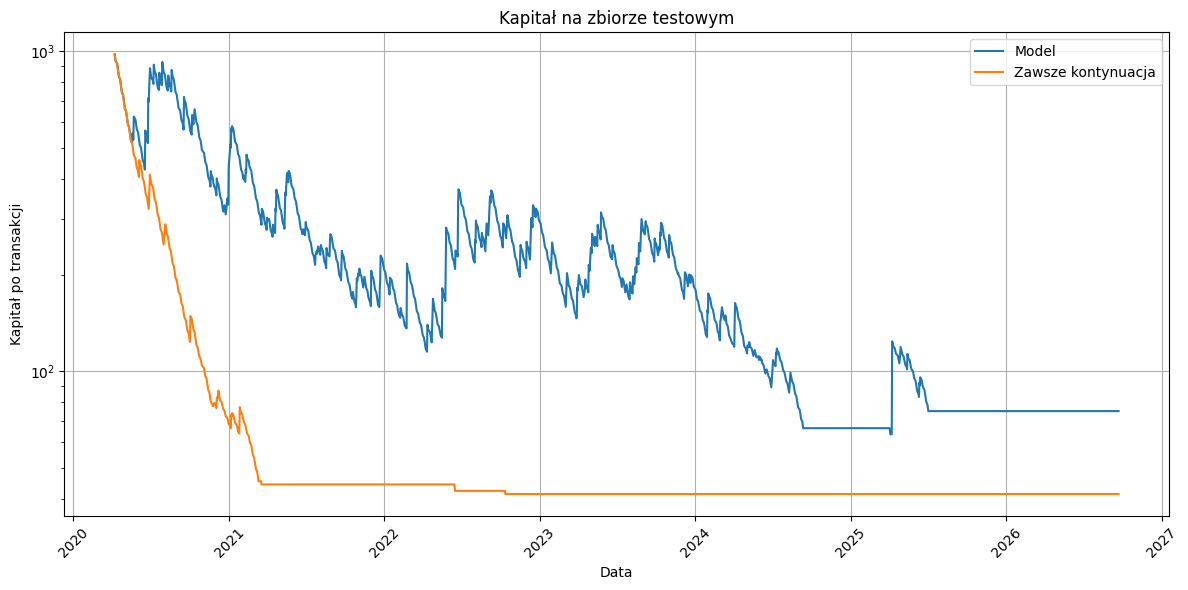

In [38]:
# =========================
# PLOT BACKTEST RESULTS
# =========================

plt.figure(figsize=(12, 6))
plt.plot(bt_test["Date"], bt_test["Capital"], label="Model")
plt.plot(bt_test_always["Date"], bt_test_always["Capital"], label="Zawsze kontynuacja")
plt.xlabel("Data")
plt.ylabel("Kapitał po transakcji")
plt.title("Kapitał na zbiorze testowym")
plt.yscale("log")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()